# 逻辑回归

在这个练习中，你将实现逻辑回归，并将其应用于两个不同的数据集。


# 大纲
- [ 1 - 包 ](#1)
- [ 2 - 逻辑回归](#2)
  - [ 2.1 问题描述](#2.1)
  - [ 2.2 加载并可视化数据](#2.2)
  - [ 2.3  Sigmoid 函数](#2.3)
  - [ 2.4 逻辑回归的代价函数](#2.4)
  - [ 2.5 逻辑回归的梯度](#2.5)
  - [ 2.6 使用梯度下降学习参数 ](#2.6)
  - [ 2.7 绘制决策边界](#2.7)
  - [ 2.8 评估逻辑回归](#2.8)
- [ 3 - 正则化逻辑回归](#3)
  - [ 3.1 问题描述](#3.1)
  - [ 3.2 加载并可视化数据](#3.2)
  - [ 3.3 特征映射](#3.3)
  - [ 3.4 正则化逻辑回归的代价函数](#3.4)
  - [ 3.5 正则化逻辑回归的梯度](#3.5)
  - [ 3.6 使用梯度下降学习参数](#3.6)
  - [ 3.7 绘制决策边界](#3.7)
  - [ 3.8 评估正则化逻辑回归模型](#3.8)

_**注意：** 为避免自动评分器报错，你不允许编辑或删除本实验中的非评分单元格。也请不要添加任何新单元格。
**一旦你通过了本作业**，想要尝试任何非评分代码，可以按照本 notebook 底部的说明操作。_

<a name="1"></a>
## 1 - 包

首先，让我们运行下面的单元格，导入你在本作业中需要用到的所有包。
- [numpy](www.numpy.org) 是用 Python 进行科学计算的基础包。
- [matplotlib](http://matplotlib.org) 是 Python 中著名的绘图库。
-  ``utils.py`` 包含本作业的辅助函数。你不需要修改此文件中的代码。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utils import *
import copy
import math

%matplotlib inline

<a name="2"></a>
## 2 - 逻辑回归

在本练习的这一部分，你将建立一个逻辑回归模型，来预测一名学生是否会被大学录取。

<a name="2.1"></a>
### 2.1 问题描述

假设你是某大学院系的管理者，你想根据申请者在两次考试中的成绩来确定每位申请者的录取机会。
* 你有以往申请者的历史数据，可将其用作逻辑回归的训练集。
* 对每个训练样本，你有申请者在两次考试中的分数以及录取决定。
* 你的任务是建立一个分类模型，根据这两次考试的分数来估计申请者的录取概率。

<a name="2.2"></a>
### 2.2 加载并可视化数据

你将从加载本任务的数据集开始。
- 下面显示的 `load_dataset()` 函数将数据加载到变量 `X_train` 和 `y_train` 中
  - `X_train` 包含一名学生两次考试的成绩
  - `y_train` 是录取决定
      - 如果学生被录取，则 `y_train = 1`
      - 如果学生未被录取，则 `y_train = 0`
  - `X_train` 和 `y_train` 都是 numpy 数组。

In [2]:
# load dataset
X_train, y_train = load_data("data/ex2data1.txt")

#### 查看变量
让我们进一步熟悉你的数据集。
- 一个好的起点就是直接打印出每个变量，看看它包含什么。

下面的代码打印 `X_train` 的前五个值以及该变量的类型。

In [3]:
print("First five elements in X_train are:\n", X_train[:5])
print("Type of X_train:",type(X_train))

First five elements in X_train are:
 [[34.62365962 78.02469282]
 [30.28671077 43.89499752]
 [35.84740877 72.90219803]
 [60.18259939 86.3085521 ]
 [79.03273605 75.34437644]]
Type of X_train: <class 'numpy.ndarray'>


现在打印 `y_train` 的前五个值

In [4]:
print("First five elements in y_train are:\n", y_train[:5])
print("Type of y_train:",type(y_train))

First five elements in y_train are:
 [0. 0. 0. 1. 1.]
Type of y_train: <class 'numpy.ndarray'>


#### 检查变量的维度

熟悉数据的另一种有用方式是查看它的维度。让我们打印 `X_train` 和 `y_train` 的形状，看看数据集中有多少个训练样本。

In [5]:
print ('The shape of X_train is: ' + str(X_train.shape))
print ('The shape of y_train is: ' + str(y_train.shape))
print ('We have m = %d training examples' % (len(y_train)))

The shape of X_train is: (100, 2)
The shape of y_train is: (100,)
We have m = 100 training examples


#### 可视化你的数据

在开始实现任何学习算法之前，如果可能的话，先可视化数据总是好的。
- 下面的代码在一个 2D 图上显示数据（如下所示），其中坐标轴是两次考试的分数，正例和负例用不同的标记显示。
- 我们使用 ``utils.py`` 文件中的一个辅助函数来生成这张图。

<img src="images/figure 1.png" width="450" height="450">

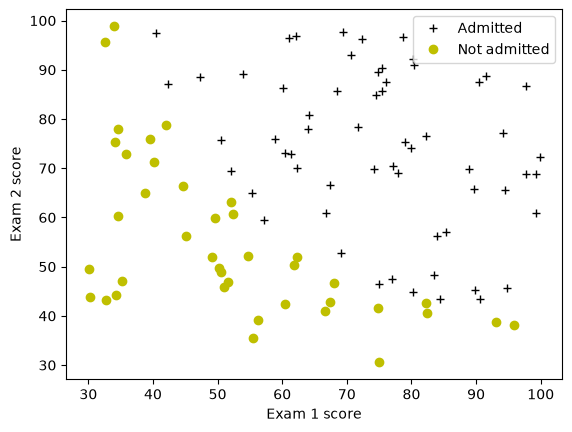

In [6]:
# Plot examples
plot_data(X_train, y_train[:], pos_label="Admitted", neg_label="Not admitted")

# Set the y-axis label
plt.ylabel('Exam 2 score') 
# Set the x-axis label
plt.xlabel('Exam 1 score') 
plt.legend(loc="upper right")
plt.show()

你的目标是建立一个逻辑回归模型来拟合这些数据。
- 有了这个模型，你就可以根据新学生在两次考试中的分数来预测他是否会被录取。

<a name="2.3"></a>
### 2.3  Sigmoid 函数

回顾一下，对于逻辑回归，模型表示为

$$ f_{\mathbf{w},b}(x) = g(\mathbf{w}\cdot \mathbf{x} + b)$$
其中函数 $g$ 是 sigmoid 函数。sigmoid 函数定义为：

$$g(z) = \frac{1}{1+e^{-z}}$$

让我们先实现 sigmoid 函数，以便本作业其余部分可以使用它。

<a name='ex-01'></a>
### 练习 1
请完成 `sigmoid` 函数，以计算

$$g(z) = \frac{1}{1+e^{-z}}$$

请注意
- `z` 并不总是单个数字，也可以是数字数组。
- 如果输入是数字数组，我们希望将 sigmoid 函数应用于输入数组中的每个值。

如果你卡住了，可以查看下面单元格之后给出的提示来帮助你实现。

In [7]:
# UNQ_C1
# GRADED FUNCTION: sigmoid

def sigmoid(z):
    """
    Compute the sigmoid of z

    Args:
        z (ndarray): A scalar, numpy array of any size.

    Returns:
        g (ndarray): sigmoid(z), with the same shape as z
         
    """
          
    ### START CODE HERE ### 
    g=1/(1+np.exp(-z))
    
    ### END SOLUTION ###  
    
    return g

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
       
   * `numpy` 有一个名为 [`np.exp()`](https://numpy.org/doc/stable/reference/generated/numpy.exp.html) 的函数，它提供了一种便捷的方式来计算输入数组（`z`）中所有元素的指数（$e^{z}$）。
 
<details>
          <summary><font size="2" color="darkblue"><b> 点击获取更多提示</b></font></summary>
        
  - 你可以把 $e^{-z}$ 写成代码 `np.exp(-z)` 
    
  - 你可以把 $1/e^{-z}$ 写成代码 `1/np.exp(-z)` 
    
    如果你仍然卡住，可以查看下面给出的提示，弄清楚如何计算 `g` 
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 g 的提示</b></font></summary>
        <code>g = 1 / (1 + np.exp(-z))</code>
    </details>


</details>

完成后，试着在下面的单元格中调用 `sigmoid(x)` 来测试几个值。
- 对于较大的正 x 值，sigmoid 应接近 1；而对于较大的负值，sigmoid 应接近 0。
- 计算 `sigmoid(0)` 应当恰好得到 0.5。

In [8]:
# Note: You can edit this value
value = 0

print (f"sigmoid({value}) = {sigmoid(value)}")

sigmoid(0) = 0.5


**预期输出**：
<table>
  <tr>
    <td> <b>sigmoid(0)<b></td>
    <td> 0.5 </td> 
  </tr>
</table>
    
- 如前所述，你的代码也应当适用于向量和矩阵。对于矩阵，你的函数应当对每个元素执行 sigmoid 函数。

In [9]:
print ("sigmoid([ -1, 0, 1, 2]) = " + str(sigmoid(np.array([-1, 0, 1, 2]))))

# UNIT TESTS
from public_tests import *
sigmoid_test(sigmoid)

sigmoid([ -1, 0, 1, 2]) = [0.26894142 0.5        0.73105858 0.88079708]
All tests passed!


**预期输出**：
<table>
  <tr>
    <td><b>sigmoid([-1, 0, 1, 2])<b></td> 
    <td>[0.26894142        0.5           0.73105858        0.88079708]</td> 
  </tr>    
  
</table>

<a name="2.4"></a>
### 2.4 逻辑回归的代价函数

在本节中，你将实现逻辑回归的代价函数。

<a name='ex-02'></a>
### 练习 2

请使用下面的方程完成 `compute_cost` 函数。

回顾一下，对于逻辑回归，代价函数的形式为

$$ J(\mathbf{w},b) = \frac{1}{m}\sum_{i=0}^{m-1} \left[ loss(f_{\mathbf{w},b}(\mathbf{x}^{(i)}), y^{(i)}) \right] \tag{1}$$

其中
* m 是数据集中的训练样本数量


* $loss(f_{\mathbf{w},b}(\mathbf{x}^{(i)}), y^{(i)})$ 是单个数据点的代价，即 - 

    $$loss(f_{\mathbf{w},b}(\mathbf{x}^{(i)}), y^{(i)}) = (-y^{(i)} \log\left(f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) - \left( 1 - y^{(i)}\right) \log \left( 1 - f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) \tag{2}$$
    
    
*  $f_{\mathbf{w},b}(\mathbf{x}^{(i)})$ 是模型的预测，而 $y^{(i)}$ 是实际标签

*  $f_{\mathbf{w},b}(\mathbf{x}^{(i)}) = g(\mathbf{w} \cdot \mathbf{x^{(i)}} + b)$，其中函数 $g$ 是 sigmoid 函数。
    * 在计算 $f_{\mathbf{w},b}(\mathbf{x}^{(i)}) = g(z_{\mathbf{w},b}(\mathbf{x}^{(i)}))$ 之前，先计算一个中间变量 $z_{\mathbf{w},b}(\mathbf{x}^{(i)}) = \mathbf{w} \cdot \mathbf{x^{(i)}} + b = w_0x^{(i)}_0 + ... + w_{n-1}x^{(i)}_{n-1} + b$（其中 $n$ 是特征数量）可能会有帮助

注意：
* 在做这部分时，请记住变量 `X_train` 和 `y_train` 不是标量值，而是形状分别为 ($m, n$) 和 ($m$,1) 的矩阵，其中 $n$ 是特征数量，$m$ 是训练样本数量。
* 你可以在这一部分使用你上面实现的 sigmoid 函数。

如果你卡住了，可以查看下面单元格之后给出的提示来帮助你实现。

In [10]:
# UNQ_C2
# GRADED FUNCTION: compute_cost
def compute_cost(X, y, w, b, *argv):
    """
    Computes the cost over all examples
    Args:
      X : (ndarray Shape (m,n)) data, m examples by n features
      y : (ndarray Shape (m,))  target value 
      w : (ndarray Shape (n,))  values of parameters of the model      
      b : (scalar)              value of bias parameter of the model
      *argv : unused, for compatibility with regularized version below
    Returns:
      total_cost : (scalar) cost 
    """

    m, n = X.shape
    
    ### START CODE HERE ###
    total_cost=0
    for i in range(m):
        z=np.dot(X[i,:],w)+b
        f=sigmoid(z)
        total_cost=total_cost-(y[i]*np.log(f)+(1-y[i])*(np.log(1-f)))
    total_cost=total_cost/m
    
    ### END CODE HERE ### 

    return total_cost

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
    
   * 你可以这样在代码中表示求和运算符，例如 $h = \sum\limits_{i = 0}^{m-1} 2i$：
    ```python 
        h = 0
        for i in range(m):
            h = h + 2*i
    ```
  
   * 在本例中，你可以用 for 循环遍历 `X` 中的所有样本，并将每次迭代得到的 `loss` 累加到一个在循环外初始化的变量（`loss_sum`）中。

   * 然后，你可以返回 `total_cost`，即 `loss_sum` 除以 `m`。
   * 如果你刚接触 Python，请检查你的代码是否使用一致的空格或制表符正确缩进。否则，它可能产生不同的输出或引发 `IndentationError: unexpected indent` 错误。你可以参考我们社区中的[这个主题](https://community.deeplearning.ai/t/indentation-in-python-indentationerror-unexpected-indent/159398)了解详情。
     
    <details>
          <summary><font size="2" color="darkblue"><b> 点击获取更多提示</b></font></summary>
        
    * 下面是这个函数整体实现的结构示例
        
    ```python 
    def compute_cost(X, y, w, b, *argv):
        m, n = X.shape
    
        ### START CODE HERE ###
        loss_sum = 0 
        
        # Loop over each training example
        for i in range(m): 
            
            # First calculate z_wb = w[0]*X[i][0]+...+w[n-1]*X[i][n-1]+b
            z_wb = 0 
            # Loop over each feature
            for j in range(n): 
                # Add the corresponding term to z_wb
                z_wb_ij = # Your code here to calculate w[j] * X[i][j]
                z_wb += z_wb_ij # equivalent to z_wb = z_wb + z_wb_ij
            # Add the bias term to z_wb
            z_wb += b # equivalent to z_wb = z_wb + b
        
            f_wb = # Your code here to calculate prediction f_wb for a training example
            loss =  # Your code here to calculate loss for a training example
            
            loss_sum += loss # equivalent to loss_sum = loss_sum + loss
        
        total_cost = (1 / m) * loss_sum  
        ### END CODE HERE ### 
        
        return total_cost
    ```
    
    如果你仍然卡住，可以查看下面给出的提示，弄清楚如何计算 `z_wb_ij`、`f_wb` 和 `cost`。
    <details>
          <summary><font size="2" color="darkblue"><b>计算 z_wb_ij 的提示</b></font></summary>
           &emsp; &emsp; <code>z_wb_ij = w[j]*X[i][j] </code>
    </details>
        
    <details>
          <summary><font size="2" color="darkblue"><b>计算 f_wb 的提示</b></font></summary>
           &emsp; &emsp; $f_{\mathbf{w},b}(\mathbf{x}^{(i)}) = g(z_{\mathbf{w},b}(\mathbf{x}^{(i)}))$，其中 $g$ 是 sigmoid 函数。你可以直接调用上面实现的 `sigmoid` 函数。
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 f 的更多提示</b></font></summary>
               &emsp; &emsp; 你可以这样计算 f_wb：<code>f_wb = sigmoid(z_wb) </code>
           </details>
    </details>

     <details>
          <summary><font size="2" color="darkblue"><b>计算 loss 的提示</b></font></summary>
          &emsp; &emsp; 你可以使用 <a href="https://numpy.org/doc/stable/reference/generated/numpy.log.html">np.log</a> 函数来计算对数
          <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 loss 的更多提示</b></font></summary>
              &emsp; &emsp; 你可以这样计算 loss：<code>loss =  -y[i] * np.log(f_wb) - (1 - y[i]) * np.log(1 - f_wb)</code>
          </details>
    </details>
        
    </details>

</details>

运行下面的单元格，用参数 $w$ 和 $b$ 的两种不同初始化来检查你对 `compute_cost` 函数的实现

In [11]:
m, n = X_train.shape

# Compute and display cost with w and b initialized to zeros
initial_w = np.zeros(n)
initial_b = 0.
cost = compute_cost(X_train, y_train, initial_w, initial_b)
print('Cost at initial w and b (zeros): {:.3f}'.format(cost))

Cost at initial w and b (zeros): 0.693


**预期输出**：
<table>
  <tr>
    <td> <b>初始 w 和 b（零）处的代价<b></td>
    <td> 0.693 </td> 
  </tr>
</table>

In [12]:
# Compute and display cost with non-zero w and b
test_w = np.array([0.2, 0.2])
test_b = -24.
cost = compute_cost(X_train, y_train, test_w, test_b)

print('Cost at test w and b (non-zeros): {:.3f}'.format(cost))


# UNIT TESTS
compute_cost_test(compute_cost)

Cost at test w and b (non-zeros): 0.218
All tests passed!


**预期输出**：
<table>
  <tr>
    <td> <b>测试 w 和 b（非零）处的代价：<b></td>
    <td> 0.218 </td> 
  </tr>
</table>

<a name="2.5"></a>
### 2.5 逻辑回归的梯度

在本节中，你将实现逻辑回归的梯度。

回顾一下，梯度下降算法为：

$$\begin{align*}& \text{repeat until convergence:} \; \lbrace \newline \; & b := b -  \alpha \frac{\partial J(\mathbf{w},b)}{\partial b} \newline       \; & w_j := w_j -  \alpha \frac{\partial J(\mathbf{w},b)}{\partial w_j} \tag{1}  \; & \text{for j := 0..n-1}\newline & \rbrace\end{align*}$$

其中，参数 $b$、$w_j$ 全部同时更新


<a name='ex-03'></a>
### 练习 3

请完成 `compute_gradient` 函数，根据下面的方程 (2) 和 (3) 计算 $\frac{\partial J(\mathbf{w},b)}{\partial w}$、$\frac{\partial J(\mathbf{w},b)}{\partial b}$。

$$
\frac{\partial J(\mathbf{w},b)}{\partial b}  = \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - \mathbf{y}^{(i)}) \tag{2}
$$
$$
\frac{\partial J(\mathbf{w},b)}{\partial w_j}  = \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - \mathbf{y}^{(i)})x_{j}^{(i)} \tag{3}
$$
* m 是数据集中的训练样本数量

    
*  $f_{\mathbf{w},b}(x^{(i)})$ 是模型的预测，而 $y^{(i)}$ 是实际标签


- **注意**：虽然这个梯度看起来与线性回归的梯度相同，但公式实际上是不同的，因为线性和逻辑回归对 $f_{\mathbf{w},b}(x)$ 的定义不同。

和之前一样，你可以使用上面实现的 sigmoid 函数；如果你卡住了，可以查看下面单元格之后给出的提示来帮助你实现。

In [13]:
# UNQ_C3
# GRADED FUNCTION: compute_gradient
def compute_gradient(X, y, w, b, *argv): 
    """
    Computes the gradient for logistic regression 
 
    Args:
      X : (ndarray Shape (m,n)) data, m examples by n features
      y : (ndarray Shape (m,))  target value 
      w : (ndarray Shape (n,))  values of parameters of the model      
      b : (scalar)              value of bias parameter of the model
      *argv : unused, for compatibility with regularized version below
    Returns
      dj_dw : (ndarray Shape (n,)) The gradient of the cost w.r.t. the parameters w. 
      dj_db : (scalar)             The gradient of the cost w.r.t. the parameter b. 
    """
    m, n = X.shape
    dj_dw = np.zeros(w.shape)
    dj_db = 0.

    ### START CODE HERE ### 
    for i in range(m):
        z_wb = np.dot(X[i,:],w)+b
        f_wb = sigmoid(z_wb)
        
        dj_db_i = f_wb-y[i]
        dj_db += dj_db_i
        
        for j in range(n):
            dj_dw[j] = dj_dw[j]+(f_wb-y[i])*X[i,j]
            
    dj_dw = dj_dw/m
    dj_db = dj_db/m
    ### END CODE HERE ###

        
    return dj_db, dj_dw

 <details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
    
* 下面是这个函数整体实现的结构示例
    ```python 
       def compute_gradient(X, y, w, b, *argv): 
            m, n = X.shape
            dj_dw = np.zeros(w.shape)
            dj_db = 0.
        
            ### START CODE HERE ### 
            for i in range(m):
                # Calculate f_wb (exactly as you did in the compute_cost function above)
                f_wb = 
        
                # Calculate the  gradient for b from this example
                dj_db_i = # Your code here to calculate the error
        
                # add that to dj_db
                dj_db += dj_db_i
        
                # get dj_dw for each attribute
                for j in range(n):
                    # You code here to calculate the gradient from the i-th example for j-th attribute
                    dj_dw_ij =  
                    dj_dw[j] += dj_dw_ij
        
            # divide dj_db and dj_dw by total number of examples
            dj_dw = dj_dw / m
            dj_db = dj_db / m
            ### END CODE HERE ###
       
            return dj_db, dj_dw
    ```

    * 如果你刚接触 Python，请检查你的代码是否使用一致的空格或制表符正确缩进。否则，它可能产生不同的输出或引发 `IndentationError: unexpected indent` 错误。你可以参考我们社区中的[这个主题](https://community.deeplearning.ai/t/indentation-in-python-indentationerror-unexpected-indent/159398)了解详情。
    * 如果你仍然卡住，可以查看下面给出的提示，弄清楚如何计算 `f_wb`、`dj_db_i` 和 `dj_dw_ij` 
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 f_wb 的提示</b></font></summary>
           &emsp; &emsp; 回顾一下，你在上面的 <code>compute_cost</code> 中计算过 f_wb——关于如何计算每个中间项的详细提示，请查看该练习下方的提示部分
           <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 f_wb 的更多提示</b></font></summary>
              &emsp; &emsp; 你可以这样计算 f_wb
               <pre>
               for i in range(m):   
                   # Calculate f_wb (exactly how you did it in the compute_cost function above)
                   z_wb = 0
                   # Loop over each feature
                   for j in range(n): 
                       # Add the corresponding term to z_wb
                       z_wb_ij = X[i, j] * w[j]
                       z_wb += z_wb_ij
            
                   # Add bias term 
                   z_wb += b
        
                   # Calculate the prediction from the model
                   f_wb = sigmoid(z_wb)
    </details>
        
    </details>
    <details>
          <summary><font size="2" color="darkblue"><b>计算 dj_db_i 的提示</b></font></summary>
           &emsp; &emsp; 你可以这样计算 dj_db_i：<code>dj_db_i = f_wb - y[i]</code>
    </details>
        
    <details>
          <summary><font size="2" color="darkblue"><b>计算 dj_dw_ij 的提示</b></font></summary>
        &emsp; &emsp; 你可以这样计算 dj_dw_ij：<code>dj_dw_ij = (f_wb - y[i])* X[i][j]</code>
    </details>

</details>

运行下面的单元格，用参数 $w$ 和 $b$ 的两种不同初始化来检查你对 `compute_gradient` 函数的实现

In [14]:
# Compute and display gradient with w and b initialized to zeros
initial_w = np.zeros(n)
initial_b = 0.

dj_db, dj_dw = compute_gradient(X_train, y_train, initial_w, initial_b)
print(f'dj_db at initial w and b (zeros):{dj_db}' )
print(f'dj_dw at initial w and b (zeros):{dj_dw.tolist()}' )

dj_db at initial w and b (zeros):-0.1
dj_dw at initial w and b (zeros):[-12.00921658929115, -11.262842205513591]


**预期输出**：
<table>
  <tr>
    <td> <b>初始 w 和 b（零）处的 dj_db<b></td>
    <td> -0.1 </td> 
  </tr>
  <tr>
    <td> <b>初始 w 和 b（零）处的 dj_dw：<b></td>
    <td> [-12.00921658929115, -11.262842205513591] </td> 
  </tr>
</table>

In [15]:
# Compute and display cost and gradient with non-zero w and b
test_w = np.array([ 0.2, -0.5])
test_b = -24
dj_db, dj_dw  = compute_gradient(X_train, y_train, test_w, test_b)

print('dj_db at test w and b:', dj_db)
print('dj_dw at test w and b:', dj_dw.tolist())

# UNIT TESTS    
compute_gradient_test(compute_gradient)

dj_db at test w and b: -0.5999999999991071
dj_dw at test w and b: [-44.831353617873795, -44.37384124953978]
All tests passed!


**预期输出**：
<table>
  <tr>
    <td> <b>测试 w 和 b（非零）处的 dj_db<b></td>
    <td> -0.5999999999991071 </td> 
  </tr>
  <tr>
    <td> <b>测试 w 和 b（非零）处的 dj_dw：<b></td>
    <td>  [-44.8313536178737957, -44.37384124953978] </td> 
  </tr>
</table>

<a name="2.6"></a>
### 2.6 使用梯度下降学习参数

与上一个作业类似，你现在将使用梯度下降来找到逻辑回归模型的最优参数。
- 这部分你不需要实现任何东西。只需运行下面的单元格。

- 验证梯度下降是否正常工作的一个好方法，是查看 $J(\mathbf{w},b)$ 的值，并检查它是否每一步都在下降。

- 假设你已经正确实现了梯度并计算了代价，你的 $J(\mathbf{w},b)$ 值应当永远不会增加，并应在算法结束时收敛到一个稳定值。

In [16]:
def gradient_descent(X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters, lambda_): 
    """
    Performs batch gradient descent to learn theta. Updates theta by taking 
    num_iters gradient steps with learning rate alpha
    
    Args:
      X :    (ndarray Shape (m, n) data, m examples by n features
      y :    (ndarray Shape (m,))  target value 
      w_in : (ndarray Shape (n,))  Initial values of parameters of the model
      b_in : (scalar)              Initial value of parameter of the model
      cost_function :              function to compute cost
      gradient_function :          function to compute gradient
      alpha : (float)              Learning rate
      num_iters : (int)            number of iterations to run gradient descent
      lambda_ : (scalar, float)    regularization constant
      
    Returns:
      w : (ndarray Shape (n,)) Updated values of parameters of the model after
          running gradient descent
      b : (scalar)                Updated value of parameter of the model after
          running gradient descent
    """
    
    # number of training examples
    m = len(X)
    
    # An array to store cost J and w's at each iteration primarily for graphing later
    J_history = []
    w_history = []
    
    for i in range(num_iters):

        # Calculate the gradient and update the parameters
        dj_db, dj_dw = gradient_function(X, y, w_in, b_in, lambda_)   

        # Update Parameters using w, b, alpha and gradient
        w_in = w_in - alpha * dj_dw               
        b_in = b_in - alpha * dj_db              
       
        # Save cost J at each iteration
        if i<100000:      # prevent resource exhaustion 
            cost =  cost_function(X, y, w_in, b_in, lambda_)
            J_history.append(cost)

        # Print cost every at intervals 10 times or as many iterations if < 10
        if i% math.ceil(num_iters/10) == 0 or i == (num_iters-1):
            w_history.append(w_in)
            print(f"Iteration {i:4}: Cost {float(J_history[-1]):8.2f}   ")
        
    return w_in, b_in, J_history, w_history #return w and J,w history for graphing

现在让我们运行上面的梯度下降算法，来为我们的数据集学习参数。

**注意**
下面的代码块运行需要几分钟，尤其是非向量化的版本。你可以减小 `iterations` 来测试你的实现并更快地迭代。如果你之后有时间，试着运行 100,000 次迭代以获得更好的结果。

In [17]:
np.random.seed(1)
initial_w = 0.01 * (np.random.rand(2) - 0.5)
initial_b = -8

# Some gradient descent settings
iterations = 10000
alpha = 0.001

w,b, J_history,_ = gradient_descent(X_train ,y_train, initial_w, initial_b, 
                                   compute_cost, compute_gradient, alpha, iterations, 0)

Iteration    0: Cost     0.96   
Iteration 1000: Cost     0.31   
Iteration 2000: Cost     0.30   
Iteration 3000: Cost     0.30   
Iteration 4000: Cost     0.30   
Iteration 5000: Cost     0.30   
Iteration 6000: Cost     0.30   
Iteration 7000: Cost     0.30   
Iteration 8000: Cost     0.30   
Iteration 9000: Cost     0.30   
Iteration 9999: Cost     0.30   


<details>
<summary>
    <b>预期输出：Cost     0.30，（点击查看详情）：</b>
</summary>

    # With the following settings
    np.random.seed(1)
    initial_w = 0.01 * (np.random.rand(2) - 0.5)
    initial_b = -8
    iterations = 10000
    alpha = 0.001
    #

```
Iteration    0: Cost     0.96   
Iteration 1000: Cost     0.31   
Iteration 2000: Cost     0.30   
Iteration 3000: Cost     0.30   
Iteration 4000: Cost     0.30   
Iteration 5000: Cost     0.30   
Iteration 6000: Cost     0.30   
Iteration 7000: Cost     0.30   
Iteration 8000: Cost     0.30   
Iteration 9000: Cost     0.30   
Iteration 9999: Cost     0.30   
```

<a name="2.7"></a>
### 2.7 绘制决策边界

现在我们将使用梯度下降得到的最终参数来绘制线性拟合。如果你正确实现了前面的部分，你应当看到类似下面这张图的图：
<img src="images/figure 2.png"  width="450" height="450">

我们将使用 `utils.py` 文件中的一个辅助函数来创建这张图。

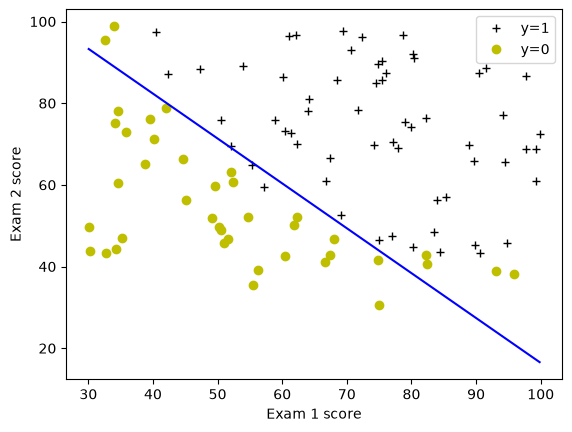

In [18]:
plot_decision_boundary(w, b, X_train, y_train)
# Set the y-axis label
plt.ylabel('Exam 2 score') 
# Set the x-axis label
plt.xlabel('Exam 1 score') 
plt.legend(loc="upper right")
plt.show()

<a name="2.8"></a>
### 2.8 评估逻辑回归

我们可以通过查看学到的模型在训练集上的预测效果，来评估我们所找到参数的质量。

你将在下面实现 `predict` 函数来做到这一点。

<a name='ex-04'></a>
### 练习 4

请完成 `predict` 函数，在给定数据集以及学到的参数向量 $w$ 和 $b$ 的情况下，产生 `1` 或 `0` 的预测。
- 首先你需要为每个样本计算模型的预测 $f(x^{(i)}) = g(w \cdot x^{(i)} + b)$
    - 你已经在上面的部分实现过这个
- 我们将模型的输出（$f(x^{(i)})$）解释为在给定 $x^{(i)}$、并由 $w$ 参数化的条件下 $y^{(i)}=1$ 的概率。
- 因此，要从逻辑回归模型得到最终预测（$y^{(i)}=0$ 或 $y^{(i)}=1$），你可以使用如下启发式规则——

  如果 $f(x^{(i)}) >= 0.5$，预测 $y^{(i)}=1$
  
  如果 $f(x^{(i)}) < 0.5$，预测 $y^{(i)}=0$
    
如果你卡住了，可以查看下面单元格之后给出的提示来帮助你实现。

In [19]:
# UNQ_C4
# GRADED FUNCTION: predict

def predict(X, w, b): 
    """
    Predict whether the label is 0 or 1 using learned logistic
    regression parameters w
    
    Args:
      X : (ndarray Shape (m,n)) data, m examples by n features
      w : (ndarray Shape (n,))  values of parameters of the model      
      b : (scalar)              value of bias parameter of the model

    Returns:
      p : (ndarray (m,)) The predictions for X using a threshold at 0.5
    """
    # number of training examples
    m, n = X.shape   
    p = np.zeros(m)
   
    ### START CODE HERE ### 
    # Loop over each example
    for i in range(m):   
        z_wb = np.dot(X[i,:],w)+b
        
        # Calculate the prediction for this example
        f_wb = sigmoid(z_wb)

        # Apply the threshold
        p[i] = f_wb>=0.5
        
    ### END CODE HERE ### 
    return p

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
    
* 下面是这个函数整体实现的结构示例
    ```python 
       def predict(X, w, b): 
            # number of training examples
            m, n = X.shape   
            p = np.zeros(m)
   
            ### START CODE HERE ### 
            # Loop over each example
            for i in range(m):   
                
                # Calculate f_wb (exactly how you did it in the compute_cost function above) 
                # using a couple of lines of code
                f_wb = 

                # Calculate the prediction for that training example 
                p[i] = # Your code here to calculate the prediction based on f_wb
        
            ### END CODE HERE ### 
            return p
    ```
  
    如果你仍然卡住，可以查看下面给出的提示，弄清楚如何计算 `f_wb` 和 `p[i]` 
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 f_wb 的提示</b></font></summary>
           &emsp; &emsp; 回顾一下，你在上面的 <code>compute_cost</code> 中计算过 f_wb——关于如何计算每个中间项的详细提示，请查看该练习下方的提示部分
           <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 f_wb 的更多提示</b></font></summary>
              &emsp; &emsp; 你可以这样计算 f_wb
               <pre>
               for i in range(m):   
                   # Calculate f_wb (exactly how you did it in the compute_cost function above)
                   z_wb = 0
                   # Loop over each feature
                   for j in range(n): 
                       # Add the corresponding term to z_wb
                       z_wb_ij = X[i, j] * w[j]
                       z_wb += z_wb_ij
            
                   # Add bias term 
                   z_wb += b
        
                   # Calculate the prediction from the model
                   f_wb = sigmoid(z_wb)
    </details>
        
    </details>
    <details>
          <summary><font size="2" color="darkblue"><b>计算 p[i] 的提示</b></font></summary>
           &emsp; &emsp; 举个例子，如果你想表示当 y 小于 3 时 x = 1，否则 x = 0，你可以在代码中表达为 <code>x = y < 3 </code>。现在对 p[i] 做同样的事：当 f_wb >= 0.5 时 p[i] = 1，否则为 0。
           <details>
              <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 p[i] 的更多提示</b></font></summary>
              &emsp; &emsp; 你可以这样计算 p[i]：<code>p[i] = f_wb >= 0.5</code>
          </details>
    </details>

</details>

一旦你完成了 `predict` 函数，让我们运行下面的代码，通过计算分类器答对的样本百分比来报告它的训练准确率。

In [20]:
# Test your predict code
np.random.seed(1)
tmp_w = np.random.randn(2)
tmp_b = 0.3    
tmp_X = np.random.randn(4, 2) - 0.5

tmp_p = predict(tmp_X, tmp_w, tmp_b)
print(f'Output of predict: shape {tmp_p.shape}, value {tmp_p}')

# UNIT TESTS        
predict_test(predict)

Output of predict: shape (4,), value [0. 1. 1. 1.]
All tests passed!


**预期输出**

<table>
  <tr>
    <td> <b>predict 的输出：形状 (4,)，值 [0. 1. 1. 1.]<b></td>
  </tr>
</table>

现在让我们用它来计算训练集上的准确率

In [21]:
#Compute accuracy on our training set
p = predict(X_train, w,b)
print('Train Accuracy: %f'%(np.mean(p == y_train) * 100))

Train Accuracy: 92.000000


<table>
  <tr>
    <td> <b>训练准确率（约）：<b></td>
    <td> 92.00 </td> 
  </tr>
</table>

<a name="3"></a>
## 3 - 正则化逻辑回归

在本练习的这一部分，你将实现正则化逻辑回归，以预测来自制造工厂的微芯片是否通过质量保证（QA）。在 QA 期间，每个微芯片都要经过各种测试，以确保其功能正常。

<a name="3.1"></a>
### 3.1 问题描述

假设你是该工厂的产品经理，你有一些微芯片在两项不同测试上的测试结果。
- 从这两项测试中，你想确定这些微芯片应当被接受还是被拒绝。
- 为帮助你做出决定，你有一个关于以往微芯片测试结果的数据集，你可以从中建立一个逻辑回归模型。

<a name="3.2"></a>
### 3.2 加载并可视化数据

与本练习前面的部分类似，让我们先加载本任务的数据集并将其可视化。

- 下面显示的 `load_dataset()` 函数将数据加载到变量 `X_train` 和 `y_train` 中
  - `X_train` 包含微芯片在两项测试中的测试结果
  - `y_train` 包含 QA 的结果
      - 如果微芯片被接受，则 `y_train = 1`
      - 如果微芯片被拒绝，则 `y_train = 0`
  - `X_train` 和 `y_train` 都是 numpy 数组。

In [22]:
# load dataset
X_train, y_train = load_data("data/ex2data2.txt")

#### 查看变量

下面的代码打印 `X_train` 和 `y_train` 的前五个值以及变量的类型。

In [23]:
# print X_train
print("X_train:", X_train[:5])
print("Type of X_train:",type(X_train))

# print y_train
print("y_train:", y_train[:5])
print("Type of y_train:",type(y_train))

X_train: [[ 0.051267  0.69956 ]
 [-0.092742  0.68494 ]
 [-0.21371   0.69225 ]
 [-0.375     0.50219 ]
 [-0.51325   0.46564 ]]
Type of X_train: <class 'numpy.ndarray'>
y_train: [1. 1. 1. 1. 1.]
Type of y_train: <class 'numpy.ndarray'>


#### 检查变量的维度

熟悉数据的另一种有用方式是查看它的维度。让我们打印 `X_train` 和 `y_train` 的形状，看看数据集中有多少个训练样本。

In [24]:
print ('The shape of X_train is: ' + str(X_train.shape))
print ('The shape of y_train is: ' + str(y_train.shape))
print ('We have m = %d training examples' % (len(y_train)))

The shape of X_train is: (118, 2)
The shape of y_train is: (118,)
We have m = 118 training examples


#### 可视化你的数据

辅助函数 `plot_data`（来自 `utils.py`）用于生成类似图 3 的图形，其中坐标轴是两项测试的分数，正例（y = 1，接受）和负例（y = 0，拒绝）用不同的标记显示。

<img src="images/figure 3.png"  width="450" height="450">

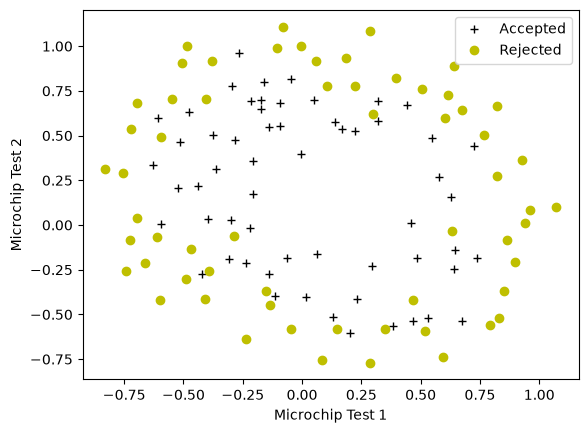

In [25]:
# Plot examples
plot_data(X_train, y_train[:], pos_label="Accepted", neg_label="Rejected")

# Set the y-axis label
plt.ylabel('Microchip Test 2') 
# Set the x-axis label
plt.xlabel('Microchip Test 1') 
plt.legend(loc="upper right")
plt.show()

图 3 显示，我们的数据集无法通过图中的一条直线被分隔成正例和负例。因此，直接应用逻辑回归在这个数据集上表现不会好，因为逻辑回归只能找到一条线性的决策边界。

<a name="3.3"></a>
### 3.3 特征映射

更好地拟合数据的一种方法是从每个数据点创建更多特征。在提供的函数 `map_feature` 中，我们将把特征映射为 $x_1$ 和 $x_2$ 的所有多项式项，最高到六次幂。

$$\mathrm{map\_feature}(x) = 
\left[\begin{array}{c}
x_1\\
x_2\\
x_1^2\\
x_1 x_2\\
x_2^2\\
x_1^3\\
\vdots\\
x_1 x_2^5\\
x_2^6\end{array}\right]$$

作为这种映射的结果，我们的两特征向量（两项 QA 测试的分数）被转换成了一个 27 维的向量。

- 在这个更高维特征向量上训练的逻辑回归分类器将具有更复杂的决策边界，并且在我们的二维图中绘制时将是非线性的。
- 我们已经在 utils.py 中为你提供了 `map_feature` 函数。

In [26]:
print("Original shape of data:", X_train.shape)

mapped_X =  map_feature(X_train[:, 0], X_train[:, 1])
print("Shape after feature mapping:", mapped_X.shape)

Original shape of data: (118, 2)
Shape after feature mapping: (118, 27)


让我们也打印 `X_train` 和 `mapped_X` 的前几个元素，以查看这一变换。

In [27]:
print("X_train[0]:", X_train[0])
print("mapped X_train[0]:", mapped_X[0])

X_train[0]: [0.051267 0.69956 ]
mapped X_train[0]: [5.12670000e-02 6.99560000e-01 2.62830529e-03 3.58643425e-02
 4.89384194e-01 1.34745327e-04 1.83865725e-03 2.50892595e-02
 3.42353606e-01 6.90798869e-06 9.42624411e-05 1.28625106e-03
 1.75514423e-02 2.39496889e-01 3.54151856e-07 4.83255257e-06
 6.59422333e-05 8.99809795e-04 1.22782870e-02 1.67542444e-01
 1.81563032e-08 2.47750473e-07 3.38066048e-06 4.61305487e-05
 6.29470940e-04 8.58939846e-03 1.17205992e-01]


虽然特征映射让我们能够建立更具表达能力的分类器，但它也更容易过拟合。在本练习接下来的部分，你将实现正则化逻辑回归来拟合数据，并亲眼看看正则化如何帮助对抗过拟合问题。

<a name="3.4"></a>
### 3.4 正则化逻辑回归的代价函数

在这一部分，你将实现正则化逻辑回归的代价函数。

回顾一下，对于正则化逻辑回归，代价函数的形式为
$$J(\mathbf{w},b) = \frac{1}{m}  \sum_{i=0}^{m-1} \left[ -y^{(i)} \log\left(f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) - \left( 1 - y^{(i)}\right) \log \left( 1 - f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) \right] + \frac{\lambda}{2m}  \sum_{j=0}^{n-1} w_j^2$$

将它与不带正则化的代价函数（你在上面实现过）进行比较，后者的形式为

$$ J(\mathbf{w}.b) = \frac{1}{m}\sum_{i=0}^{m-1} \left[ (-y^{(i)} \log\left(f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) - \left( 1 - y^{(i)}\right) \log \left( 1 - f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right)\right]$$

区别在于正则化项，即 $$\frac{\lambda}{2m}  \sum_{j=0}^{n-1} w_j^2$$ 
请注意，参数 $b$ 没有被正则化。

<a name='ex-05'></a>
### 练习 5

请完成下面的 `compute_cost_reg` 函数，为 $w$ 中的每个元素计算下面这一项
$$\frac{\lambda}{2m}  \sum_{j=0}^{n-1} w_j^2$$

然后，起始代码会把它加到不带正则化的代价（你在上面的 `compute_cost` 中计算过）上，以计算带正则化的代价。

如果你卡住了，可以查看下面单元格之后给出的提示来帮助你实现。

In [28]:
# UNQ_C5
def compute_cost_reg(X, y, w, b, lambda_ = 1):
    """
    Computes the cost over all examples
    Args:
      X : (ndarray Shape (m,n)) data, m examples by n features
      y : (ndarray Shape (m,))  target value 
      w : (ndarray Shape (n,))  values of parameters of the model      
      b : (scalar)              value of bias parameter of the model
      lambda_ : (scalar, float) Controls amount of regularization
    Returns:
      total_cost : (scalar)     cost 
    """

    m, n = X.shape
    
    # Calls the compute_cost function that you implemented above
    cost_without_reg = compute_cost(X, y, w, b) 
    
    # You need to calculate this value
    reg_cost = 0.
    
    ### START CODE HERE ###
    for j in range(n):
        reg_cost +=(w[j]**2)
    reg_cost=reg_cost*(lambda_/(2*m))    
    
    ### END CODE HERE ### 
    
    # Add the regularization cost to get the total cost
    total_cost = cost_without_reg + reg_cost

    return total_cost

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
    
* 下面是这个函数整体实现的结构示例
    ```python 
       def compute_cost_reg(X, y, w, b, lambda_ = 1):
   
           m, n = X.shape
    
            # Calls the compute_cost function that you implemented above
            cost_without_reg = compute_cost(X, y, w, b) 
    
            # You need to calculate this value
            reg_cost = 0.
    
            ### START CODE HERE ###
            for j in range(n):
                reg_cost_j = # Your code here to calculate the cost from w[j]
                reg_cost = reg_cost + reg_cost_j
            reg_cost = (lambda_/(2 * m)) * reg_cost
            ### END CODE HERE ### 
    
            # Add the regularization cost to get the total cost
            total_cost = cost_without_reg + reg_cost

        return total_cost
    ```
  
    如果你仍然卡住，可以查看下面给出的提示，弄清楚如何计算 `reg_cost_j` 
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 reg_cost_j 的提示</b></font></summary>
           &emsp; &emsp; 你可以这样计算 reg_cost_j：<code>reg_cost_j = w[j]**2 </code> 
    </details>
        
    </details>

</details>

运行下面的单元格，检查你对 `compute_cost_reg` 函数的实现。

In [29]:
X_mapped = map_feature(X_train[:, 0], X_train[:, 1])
np.random.seed(1)
initial_w = np.random.rand(X_mapped.shape[1]) - 0.5
initial_b = 0.5
lambda_ = 0.5
cost = compute_cost_reg(X_mapped, y_train, initial_w, initial_b, lambda_)

print("Regularized cost :", cost)

# UNIT TEST    
compute_cost_reg_test(compute_cost_reg)

Regularized cost : 0.6618252552483948
All tests passed!


**预期输出**：
<table>
  <tr>
    <td> <b>正则化代价：<b></td>
    <td> 0.6618252552483948 </td> 
  </tr>
</table>

<a name="3.5"></a>
### 3.5 正则化逻辑回归的梯度

在本节中，你将实现正则化逻辑回归的梯度。


正则化代价函数的梯度有两个组成部分。第一个 $\frac{\partial J(\mathbf{w},b)}{\partial b}$ 是一个标量，另一个是与参数 $\mathbf{w}$ 形状相同的向量，其第 $j^\mathrm{th}$ 个元素定义如下：

$$\frac{\partial J(\mathbf{w},b)}{\partial b} = \frac{1}{m}  \sum_{i=0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)})  $$

$$\frac{\partial J(\mathbf{w},b)}{\partial w_j} = \left( \frac{1}{m}  \sum_{i=0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}) x_j^{(i)} \right) + \frac{\lambda}{m} w_j  \quad\, \mbox{for $j=0...(n-1)$}$$

将它与不带正则化的代价函数的梯度（你在上面实现过）进行比较，后者的形式为
$$
\frac{\partial J(\mathbf{w},b)}{\partial b}  = \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - \mathbf{y}^{(i)}) \tag{2}
$$
$$
\frac{\partial J(\mathbf{w},b)}{\partial w_j}  = \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - \mathbf{y}^{(i)})x_{j}^{(i)} \tag{3}
$$


可以看到，$\frac{\partial J(\mathbf{w},b)}{\partial b}$ 是相同的，区别在于 $\frac{\partial J(\mathbf{w},b)}{\partial w}$ 中的下面这一项，即 $$\frac{\lambda}{m} w_j  \quad\, \mbox{for $j=0...(n-1)$}$$

<a name='ex-06'></a>
### 练习 6

请完成下面的 `compute_gradient_reg` 函数，修改下面的代码以计算下面这一项

$$\frac{\lambda}{m} w_j  \quad\, \mbox{for $j=0...(n-1)$}$$

起始代码会把这一项加到上面 `compute_gradient` 返回的 $\frac{\partial J(\mathbf{w},b)}{\partial w}$ 上，以得到正则化代价函数的梯度。


如果你卡住了，可以查看下面单元格之后给出的提示来帮助你实现。

In [30]:
# UNQ_C6
def compute_gradient_reg(X, y, w, b, lambda_ = 1): 
    """
    Computes the gradient for logistic regression with regularization
 
    Args:
      X : (ndarray Shape (m,n)) data, m examples by n features
      y : (ndarray Shape (m,))  target value 
      w : (ndarray Shape (n,))  values of parameters of the model      
      b : (scalar)              value of bias parameter of the model
      lambda_ : (scalar,float)  regularization constant
    Returns
      dj_db : (scalar)             The gradient of the cost w.r.t. the parameter b. 
      dj_dw : (ndarray Shape (n,)) The gradient of the cost w.r.t. the parameters w. 

    """
    m, n = X.shape
    
    dj_db, dj_dw = compute_gradient(X, y, w, b)

    ### START CODE HERE ###     
    dj_dw=dj_dw+(lambda_/m)*w
        
    ### END CODE HERE ###         
        
    return dj_db, dj_dw

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    
    
* 下面是这个函数整体实现的结构示例
    ```python 
    def compute_gradient_reg(X, y, w, b, lambda_ = 1): 
        m, n = X.shape
    
        dj_db, dj_dw = compute_gradient(X, y, w, b)

        ### START CODE HERE ###     
        # Loop over the elements of w
        for j in range(n): 
            
            dj_dw_j_reg = # Your code here to calculate the regularization term for dj_dw[j]
            
            # Add the regularization term  to the correspoding element of dj_dw
            dj_dw[j] = dj_dw[j] + dj_dw_j_reg
        
        ### END CODE HERE ###         
        
        return dj_db, dj_dw
    ```
  
    如果你仍然卡住，可以查看下面给出的提示，弄清楚如何计算 `dj_dw_j_reg` 
    
    <details>
          <summary><font size="2" color="darkblue"><b>计算 dj_dw_j_reg 的提示</b></font></summary>
           &emsp; &emsp; 你可以这样计算 dj_dw_j_reg：<code>dj_dw_j_reg = (lambda_ / m) * w[j] </code> 
    </details>
        
    </details>

</details>

运行下面的单元格，检查你对 `compute_gradient_reg` 函数的实现。

In [31]:
X_mapped = map_feature(X_train[:, 0], X_train[:, 1])
np.random.seed(1) 
initial_w  = np.random.rand(X_mapped.shape[1]) - 0.5 
initial_b = 0.5
 
lambda_ = 0.5
dj_db, dj_dw = compute_gradient_reg(X_mapped, y_train, initial_w, initial_b, lambda_)

print(f"dj_db: {dj_db}", )
print(f"First few elements of regularized dj_dw:\n {dj_dw[:4].tolist()}", )

# UNIT TESTS    
compute_gradient_reg_test(compute_gradient_reg)

dj_db: 0.07138288792343662
First few elements of regularized dj_dw:
 [-0.010386028450548701, 0.011409852883280122, 0.0536273463274574, 0.0031402782673134655]
All tests passed!


**预期输出**：
<table>
  <tr>
    <td> <b>dj_db:</b>0.07138288792343</td> </tr>
  <tr>
      <td> <b> 正则化 dj_dw 的前几个元素：</b> </td> </tr>
   <tr>
   <td> [[-0.010386028450548], [0.011409852883280], [0.0536273463274], [0.003140278267313]] </td> 
  </tr>
</table>

<a name="3.6"></a>
### 3.6 使用梯度下降学习参数

与前面的部分类似，你将使用上面实现的梯度下降函数来学习最优参数 $w$、$b$。
- 如果你已正确完成了正则化逻辑回归的代价和梯度，你应当能够逐步执行下一个单元格来学习参数 $w$。
- 训练好参数后，我们将用它来绘制决策边界。

**注意**

下面的代码块运行需要相当长的时间，尤其是非向量化的版本。你可以减小 `iterations` 来测试你的实现并更快地迭代。如果你之后有时间，运行 100,000 次迭代以查看更好的结果。

In [32]:
# Initialize fitting parameters
np.random.seed(1)
initial_w = np.random.rand(X_mapped.shape[1])-0.5
initial_b = 1.

# Set regularization parameter lambda_ (you can try varying this)
lambda_ = 0.01    

# Some gradient descent settings
iterations = 10000
alpha = 0.01

w,b, J_history,_ = gradient_descent(X_mapped, y_train, initial_w, initial_b, 
                                    compute_cost_reg, compute_gradient_reg, 
                                    alpha, iterations, lambda_)

Iteration    0: Cost     0.72   
Iteration 1000: Cost     0.59   
Iteration 2000: Cost     0.56   
Iteration 3000: Cost     0.53   
Iteration 4000: Cost     0.51   
Iteration 5000: Cost     0.50   
Iteration 6000: Cost     0.48   
Iteration 7000: Cost     0.47   
Iteration 8000: Cost     0.46   
Iteration 9000: Cost     0.45   
Iteration 9999: Cost     0.45   


<details>
<summary>
    <b>预期输出：Cost < 0.5  （点击查看详情）</b>
</summary>

```
# Using the following settings
#np.random.seed(1)
#initial_w = np.random.rand(X_mapped.shape[1])-0.5
#initial_b = 1.
#lambda_ = 0.01;                                          
#iterations = 10000
#alpha = 0.01
Iteration    0: Cost     0.72   
Iteration 1000: Cost     0.59   
Iteration 2000: Cost     0.56   
Iteration 3000: Cost     0.53   
Iteration 4000: Cost     0.51   
Iteration 5000: Cost     0.50   
Iteration 6000: Cost     0.48   
Iteration 7000: Cost     0.47   
Iteration 8000: Cost     0.46   
Iteration 9000: Cost     0.45   
Iteration 9999: Cost     0.45       
    
```

<a name="3.7"></a>
### 3.7 绘制决策边界
为帮助你可视化这个分类器学到的模型，我们将使用我们的 `plot_decision_boundary` 函数，它绘制出分隔正例和负例的（非线性）决策边界。

- 在该函数中，我们通过在均匀间隔的网格上计算分类器的预测来绘制非线性决策边界，然后绘制出预测从 y = 0 变为 y = 1 之处的等高线图。

- 在学习到参数 $w$、$b$ 之后，下一步是绘制一条类似图 4 的决策边界。

<img src="images/figure 4.png"  width="450" height="450">

ValueError: setting an array element with a sequence.

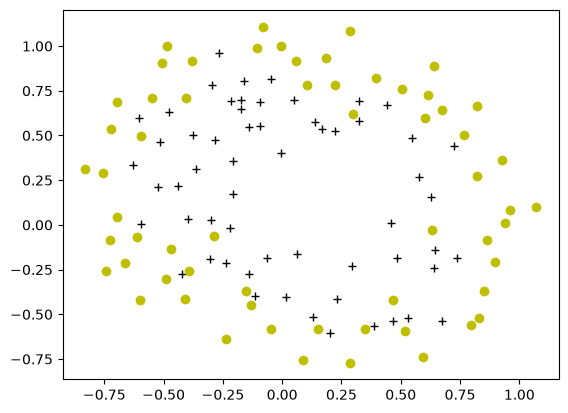

In [33]:
plot_decision_boundary(w, b, X_mapped, y_train)
# Set the y-axis label
plt.ylabel('Microchip Test 2') 
# Set the x-axis label
plt.xlabel('Microchip Test 1') 
plt.legend(loc="upper right")
plt.show()

<a name="3.8"></a>
### 3.8 评估正则化逻辑回归模型

你将使用上面实现的 `predict` 函数来计算正则化逻辑回归模型在训练集上的准确率

In [ ]:
#Compute accuracy on the training set
p = predict(X_mapped, w, b)

print('Train Accuracy: %f'%(np.mean(p == y_train) * 100))

Train Accuracy: 82.203390


**预期输出**：
<table>
  <tr>
    <td> <b>训练准确率：</b>~ 80%</td> </tr>
</table>

**恭喜你完成了本课程的最后一个实验！我们希望能在课程 2 中见到你，在那里你将使用更高级的学习算法，例如神经网络和决策树。继续学习吧！**

<details>
  <summary><font size="2" color="darkgreen"><b>如果你想尝试任何非评分代码，请点击这里。</b></font></summary>
    <p><i><b>重要提示：请只在你已经通过本作业后再这样做，以避免自动评分器出现问题。</b></i>
    <ol>
        <li> 在 notebook 的菜单上，点击 “View” > “Cell Toolbar” > “Edit Metadata”</li>
        <li> 点击你想锁定/解锁的代码单元格旁边的 “Edit Metadata” 按钮</li>
        <li> 将 “editable” 的属性值设置为：
            <ul>
                <li> “true” 如果你想解锁它 </li>
                <li> “false” 如果你想锁定它 </li>
            </ul>
        </li>
        <li> 在 notebook 的菜单上，点击 “View” > “Cell Toolbar” > “None” </li>
    </ol>
    <p> 下面是如何执行上述步骤的简短演示：
        <br>
        <img src="https://drive.google.com/uc?export=view&id=14Xy_Mb17CZVgzVAgq7NCjMVBvSae3xO1" align="center" alt="unlock_cells.gif">
</details>